In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import os
import sys
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


DATADIR = Path('../data/Cell_Cycle_Model_Runs/')

In [2]:
%matplotlib inline

In [3]:
notes = pd.read_table(Path(DATADIR,'model_run_notes.txt'))

In [4]:
notes.head()

,Runs for included model inputs are as follows:
0,"Low stiffness, +ERL"
1,"erl_7-7_1_1.csv, erl_7-7_1_2.csv, erl_7-7_1_3.csv"
2,"Int. stiffness, +ERL"
3,"erl_7-7_2_1.csv, erl_7-7_2_2.csv, erl_7-7_2_3.csv"
4,"High stiffness, +ERL"


In [5]:
cn = notes.iloc[13:37,0].to_list()
cn = [x.split(" ")[1] for x in cn]

In [6]:
cn

['Skp2',
 'p21',
 'p21p',
 'Cdh1',
 'Myc',
 'CycD',
 'CycDp21',
 'Rb',
 'pRb',
 'E2F',
 'RbE2F',
 'CycE',
 'CycEp21',
 'CycA',
 'CycAp21',
 'CycB',
 'CycBp21',
 'Cdc20',
 'BAX',
 'BAXmBCL2',
 'BH3',
 'BH3BCL2',
 'BAXm',
 'BCL2']

In [7]:
file_names = [x for x in os.listdir(DATADIR) if not "txt" in x]
file_names = [x for x in file_names if x != "st_t.csv"]

In [8]:
file_names.sort()
file_names

['dmso_7-7_1.csv',
 'dmso_7-7_2.csv',
 'dmso_7-7_3.csv',
 'erl_7-7_1_1.csv',
 'erl_7-7_1_2.csv',
 'erl_7-7_1_3.csv',
 'erl_7-7_2_1.csv',
 'erl_7-7_2_2.csv',
 'erl_7-7_2_3.csv',
 'erl_7-7_3_1.csv',
 'erl_7-7_3_2.csv',
 'erl_7-7_3_3.csv']

In [9]:
a = pd.read_csv(Path(DATADIR,file_names[0]), header=None, names=cn)

In [10]:
a.head()

,Skp2,p21,p21p,Cdh1,Myc,CycD,CycDp21,Rb,pRb,E2F,...,CycAp21,CycB,CycBp21,Cdc20,BAX,BAXmBCL2,BH3,BH3BCL2,BAXm,BCL2
0,15.0,8.0,5.0,3.0,94.0,39.0,3.0,97.00,74.0,4.0000,...,13.0,153.0,1.0,156.00,200.0,0.0,0.0,7.0,0.0,183.0
1,15.0,8.0,7.0,2.0,96.0,36.0,3.0,87.00,82.0,3.0000,...,13.0,154.0,1.0,155.47,199.0,1.0,0.0,7.0,0.0,182.0
2,15.0,9.0,5.0,3.0,93.0,34.0,4.0,103.58,64.0,1.5814,...,15.0,150.0,1.0,160.00,198.0,2.0,0.0,7.0,0.0,181.0
3,15.0,10.0,3.0,2.0,94.0,29.0,5.0,103.00,66.0,2.0000,...,16.0,147.0,1.0,158.42,198.0,2.0,0.0,8.0,0.0,180.0
4,15.0,8.0,4.0,6.0,97.0,32.0,5.0,112.88,57.0,2.8805,...,17.0,144.0,1.0,162.00,198.0,2.0,0.0,8.0,0.0,180.0


In [11]:
a.shape

(50001, 24)

In [12]:
a.insert(0, "time", a.index*0.1)

In [13]:
a.head()

,time,Skp2,p21,p21p,Cdh1,Myc,CycD,CycDp21,Rb,pRb,...,CycAp21,CycB,CycBp21,Cdc20,BAX,BAXmBCL2,BH3,BH3BCL2,BAXm,BCL2
0,0.0,15.0,8.0,5.0,3.0,94.0,39.0,3.0,97.00,74.0,...,13.0,153.0,1.0,156.00,200.0,0.0,0.0,7.0,0.0,183.0
1,0.1,15.0,8.0,7.0,2.0,96.0,36.0,3.0,87.00,82.0,...,13.0,154.0,1.0,155.47,199.0,1.0,0.0,7.0,0.0,182.0
2,0.2,15.0,9.0,5.0,3.0,93.0,34.0,4.0,103.58,64.0,...,15.0,150.0,1.0,160.00,198.0,2.0,0.0,7.0,0.0,181.0
3,0.3,15.0,10.0,3.0,2.0,94.0,29.0,5.0,103.00,66.0,...,16.0,147.0,1.0,158.42,198.0,2.0,0.0,8.0,0.0,180.0
4,0.4,15.0,8.0,4.0,6.0,97.0,32.0,5.0,112.88,57.0,...,17.0,144.0,1.0,162.00,198.0,2.0,0.0,8.0,0.0,180.0


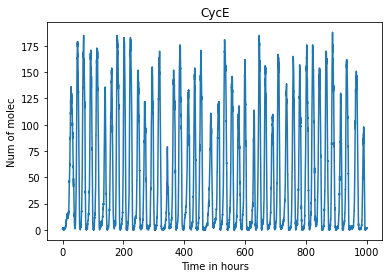

In [14]:
plt.plot(a.iloc[:10000,]['time'],a.iloc[:10000,]['CycE'])
plt.title('CycE')
plt.xlabel('Time in hours')
plt.ylabel('Num of molec')
plt.show()